In [2]:
import matplotlib.pyplot as plt
import onnx
import onnxruntime
import torch

from torch.utils.data import DataLoader

import lenet

print(torch.__version__)

2.13.0+cpu


In [3]:
torch.manual_seed(lenet.seed)

# Loading Fasion-MNIST dataset

In [4]:
from torchvision import datasets
from torchvision.transforms import v2

## Loading training/test dataset.

Training data length: 60000
Training data shape: torch.Size([1, 28, 28])


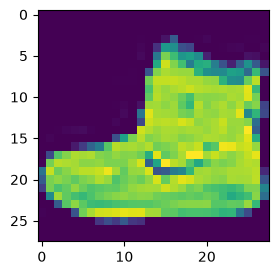

In [5]:
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])
)

print("Training data length:", len(training_data))
print("Training data shape:", training_data[0][0].shape)
plt.figure(figsize=(3, 3))
# Loaded data is an array of tuples of (image tensor, class label).
# to show image we need to pass a list of array of shape (28, 28) to plt.imshow.
plt.imshow(training_data[0][0][0,:])

Loading test set and converting to float32 since NN works.

Test data length: 10000
Pixel value: min=0.0, max=1.0


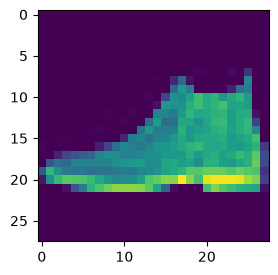

In [6]:
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True)
    ])
)

print("Test data length:", len(test_data))
print(f"Pixel value: min={test_data[0][0].min()}, max={test_data[0][0].max()}")
plt.figure(figsize=(3, 3))

# Loaded data is an array of tuples of (image tensor, class label).
# tensor is a 3D tensor of shape (1, 28, 28) for grayscale images.
# to show image we need to pass a list of array of shape (28, 28) to plt.imshow.
plt.imshow(test_data[0][0][0,:])

## Create DataLoaders to get batches

In [7]:
batch_size = 64
train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

Inspect a batch shape

In [8]:
X_batch, y_batch = next(iter(test_dataloader))
print(f'X shape: {X_batch.shape}')
print(f'y shape: {y_batch.shape}')

# check image shape
if X_batch.shape != (batch_size, 1, 28, 28):
    raise ValueError(f'Expected shape (batch_size, 1, 28, 28), but got {X_batch.shape}')
# check label shape
if y_batch.shape != (batch_size,):
    raise ValueError(f'Expected shape (batch_size,), but got {y_batch.shape}')

# check image dtype
if X_batch.dtype != torch.float32:
    raise ValueError(f'Expected dtype torch.float32, but got {X_batch.dtype}')

# check pixel valu range in [0,1]
if X_batch.min() < 0.0 or X_batch.max() > 1.0:
    raise ValueError(f'Expected pixel values in range [0, 1], but got min={X_batch.min()}, max={X_batch.max()}')

# check label range in [0,9]
if y_batch.dtype != torch.int64:
    raise ValueError(f'Expected dtype torch.int64, but got {y_batch.dtype}')
if y_batch.min() < 0 or y_batch.max() > 9:
    raise ValueError(f'Expected labels in range [0, 9], but got min={y_batch.min()}, max={y_batch.max()}')


X shape: torch.Size([64, 1, 28, 28])
y shape: torch.Size([64])


## Save sample tensors

In [9]:
images = X_batch.detach().cpu().numpy().astype("<f4")
labels = y_batch.detach().cpu().numpy().astype("<i8")
lenet.save_tensor(images, lenet.sample_filename)
lenet.save_tensor(labels, lenet.labels_filename)


# Creating a Neural Network

In [10]:
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [ ]:
model = lenet.LeNetModel().to(device)
print(model)

LeNetModel(
  (lenet_stack): Sequential(
    (0): Conv2d(1, 12, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(12, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1152, out_features=120, bias=True)
    (8): ReLU()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Sigmoid()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)


# Training NN

In [12]:
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [13]:
def train(epoch_num, dataloader, model, loss_fn, optimizer):
    num_batches = len(dataloader)

    model.train()

    for batch_num, (X, y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)

        pred = model(X)
        loss = loss_fn(pred, y)

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        # if batch_num % 100 == 0:
            # loss = loss.item()
            # accuracy = (pred.argmax(dim=1) == y).type(torch.float).sum().item() / y.size(0)
            # print(f'epoch_num={epoch_num}, sample={batch_num} ({num_batches}), loss= {loss}, accuracy= {accuracy*100:.1f}%')


def test_loop(kind, dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss = 0
    correct = 0

    with torch.no_grad():
        for batch_num, (X_test, y_test) in enumerate(dataloader):
            pred = model(X_test)
            test_loss += loss_fn(pred, y_test).item()
            correct += (pred.argmax(dim=1) == y_test).type(torch.float).sum().item()

    print(f'{kind} Data: Accuracy: {(100*correct/size):>0.1f}%, Avg loss: {test_loss/num_batches:>8f}')


epochs = 40

for epoch in range(epochs):
    print(f"-------------------------------")
    print(f"Epoch {epoch+1}")
    train(epoch, train_dataloader, model, loss_fn, optimizer)
    test_loop("Train", train_dataloader, model, loss_fn)
    test_loop("Test", test_dataloader, model, loss_fn)
    print(f"-------------------------------")


-------------------------------
Epoch 1
Train Data: Accuracy: 72.4%, Avg loss: 0.702792
Test Data: Accuracy: 71.2%, Avg loss: 0.728851
-------------------------------
-------------------------------
Epoch 2
Train Data: Accuracy: 79.8%, Avg loss: 0.532923
Test Data: Accuracy: 79.0%, Avg loss: 0.559505
-------------------------------
-------------------------------
Epoch 3
Train Data: Accuracy: 81.9%, Avg loss: 0.481637
Test Data: Accuracy: 80.6%, Avg loss: 0.514144
-------------------------------
-------------------------------
Epoch 4
Train Data: Accuracy: 82.2%, Avg loss: 0.473069
Test Data: Accuracy: 80.7%, Avg loss: 0.511105
-------------------------------
-------------------------------
Epoch 5
Train Data: Accuracy: 84.7%, Avg loss: 0.401497
Test Data: Accuracy: 83.7%, Avg loss: 0.441506
-------------------------------
-------------------------------
Epoch 6
Train Data: Accuracy: 85.9%, Avg loss: 0.380846
Test Data: Accuracy: 84.6%, Avg loss: 0.419232
------------------------------

# Save Model

In [14]:
torch.save(model.state_dict(), lenet.torch_filename)

# Load Model

In [15]:
loaded_model = lenet.LeNetModel().to(device)
loaded_model.load_state_dict(torch.load(lenet.torch_filename))

test_loop("Trained model test", test_dataloader, loaded_model, loss_fn)
test_loop("Loaded model test", test_dataloader, loaded_model, loss_fn)


Trained model test Data: Accuracy: 89.3%, Avg loss: 0.306831
Loaded model test Data: Accuracy: 89.3%, Avg loss: 0.306831


# ONNX

## Export

In [16]:
sample_input, _ = next(iter(test_dataloader))
onnx_program = torch.onnx.export(
    loaded_model,
    (torch.randn(1, 1, 28, 28)),
    lenet.onnx_filename,
    input_names=["images"],
    output_names=["logits"],
    dynamo=True,
    external_data=False)


[torch.onnx] Obtain model graph for `LeNetModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `LeNetModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


## Inspecting ONNX model

### Intenals

Print model's version, intput and outputs

In [19]:
onnx_model = onnx.load(lenet.onnx_filename)
onnx.checker.check_model(onnx_model)
print(f"onnx op_set version={onnx.defs.onnx_opset_version()}")
print(f"onnx_model.op_set_version={onnx_model.opset_import[0].version}")
print(f"onnx_model.ir_version={onnx_model.ir_version}")

model_input = onnx_model.graph.input[0]
print(f"onnx_model.input: name={model_input.name}, type={model_input.type.tensor_type.elem_type} shape={model_input.type.tensor_type.shape.dim}")

model_output = onnx_model.graph.output[0]
print(f"onnx_model.output: name={model_output.name}, type={model_output.type.tensor_type.elem_type} shape={model_output.type.tensor_type.shape.dim}")


onnx op_set version=28
onnx_model.op_set_version=20
onnx_model.ir_version=10
onnx_model.input: name=images, type=1 shape=[dim_value: 1
, dim_value: 1
, dim_value: 28
, dim_value: 28
]
onnx_model.output: name=logits, type=1 shape=[dim_value: 1
, dim_value: 10
]


# Initializer

In [20]:
for initializer in onnx_model.graph.initializer:
    dtype = onnx.TensorProto.DataType.Name(initializer.data_type)
    print(f"initializer: name={initializer.name}, type={dtype}, shape={initializer.dims}")

initializer: name=lenet_stack.0.weight, type=FLOAT, shape=[12, 1, 3, 3]
initializer: name=lenet_stack.0.bias, type=FLOAT, shape=[12]
initializer: name=lenet_stack.3.weight, type=FLOAT, shape=[32, 12, 3, 3]
initializer: name=lenet_stack.3.bias, type=FLOAT, shape=[32]
initializer: name=lenet_stack.7.weight, type=FLOAT, shape=[120, 1152]
initializer: name=lenet_stack.7.bias, type=FLOAT, shape=[120]
initializer: name=lenet_stack.9.weight, type=FLOAT, shape=[84, 120]
initializer: name=lenet_stack.9.bias, type=FLOAT, shape=[84]
initializer: name=lenet_stack.11.weight, type=FLOAT, shape=[10, 84]
initializer: name=lenet_stack.11.bias, type=FLOAT, shape=[10]
initializer: name=val_3, type=INT64, shape=[2]


# Inspecting graph

In [21]:
for node in onnx_model.graph.node:
    print(f"node: name={node.name}, op_type={node.op_type}, input={node.input}, output={node.output}")

node: name=node_conv2d, op_type=Conv, input=['images', 'lenet_stack.0.weight', 'lenet_stack.0.bias'], output=['conv2d']
node: name=node_relu, op_type=Relu, input=['conv2d'], output=['relu']
node: name=node_avg_pool2d, op_type=AveragePool, input=['relu'], output=['avg_pool2d']
node: name=node_conv2d_1, op_type=Conv, input=['avg_pool2d', 'lenet_stack.3.weight', 'lenet_stack.3.bias'], output=['conv2d_1']
node: name=node_relu_1, op_type=Relu, input=['conv2d_1'], output=['relu_1']
node: name=node_avg_pool2d_1, op_type=AveragePool, input=['relu_1'], output=['avg_pool2d_1']
node: name=node_view, op_type=Reshape, input=['avg_pool2d_1', 'val_3'], output=['view']
node: name=node_linear, op_type=Gemm, input=['view', 'lenet_stack.7.weight', 'lenet_stack.7.bias'], output=['linear']
node: name=node_relu_2, op_type=Relu, input=['linear'], output=['relu_2']
node: name=node_linear_1, op_type=Gemm, input=['relu_2', 'lenet_stack.9.weight', 'lenet_stack.9.bias'], output=['linear_1']
node: name=node_sigmoi